# Exercice : l'électricité dans 12 quartiers

## 1. Diagnostic

**1.** Forme, type de chaque colonne, nombre de valeurs manquantes par colonne et nombre de lignes en double.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")

print("Forme :", brut.shape)
print()
print("Types :")
print(brut.dtypes)
print()
print("Valeurs manquantes :")
print(brut.isna().sum())
print()
print("Lignes en double :", brut.duplicated().sum())

Forme : (300, 4)

Types :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**2.** Écritures différentes pour la colonne quartier.

In [2]:
print("Écritures différentes :", brut["quartier"].nunique())
print()
print(sorted(brut["quartier"].unique()))

Écritures différentes : 43

[' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose', 'Bas-Peu-de-Chose ', 'Bois-Verna', 'CARÉNAGE', 'CENTRE-VILLE', 'Carénage', 'Carénage ', 'Centre-ville', 'Centre-ville ', 'DELMAS 33', 'Delmas 33', 'Delmas 33 ', 'Delmas 65', 'Delmas 75', 'Delmas 75 ', 'Morne Calvaire', 'PLACE SAINT-PIERRE', 'Petite-Anse', 'Place Saint-Pierre', 'Place Saint-Pierre ', 'RUE 15', 'Rue 15', 'Rue 15 ', 'THOMASSIN', 'Thomassin', 'Thomassin ', 'bas-peu-de-chose', 'carénage', 'centre-ville', 'delmas 65', 'delmas 75', 'place saint-pierre']


**3.** Affichez les valeurs que pd.to_numeric(..., errors="coerce") ne sait pas convertir, pour kwh.

In [3]:
kwh_converti = pd.to_numeric(brut["kwh"], errors="coerce")
non_convertibles = brut.loc[kwh_converti.isna() & brut["kwh"].notna(), "kwh"]

print("Valeurs non convertibles (hors vrais manquants) :", len(non_convertibles))
print(non_convertibles.head(10).tolist())

Valeurs non convertibles (hors vrais manquants) : 52
['184410 kWh', '206280 kWh', '215140 kWh', '251 900', '274520 kWh', '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh']


## 2. Nettoyage

Une copie propre, puis une cellule par problème du diagnostic, en comptant à chaque fois.


**4.** Conversion de kwh en nombre

In [4]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].str.replace("kWh", "", regex=False).str.replace(r"\s", "", regex=True)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")

print("Manquants dans kwh :", propre["kwh"].isna().sum())
print("Type de kwh :", propre["kwh"].dtype)

Manquants dans kwh : 9
Type de kwh : float64


**5.** Harmonisation des noms de quartiers.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")
noms_officiels = {nom.lower(): nom for nom in quartiers["quartier"]}

propre["quartier"] = propre["quartier"].str.strip().str.lower().map(noms_officiels)

print("Quartiers :", propre["quartier"].nunique())
print("Noms perdus par map :", propre["quartier"].isna().sum())

Quartiers : 12
Noms perdus par map : 0


**6.** Supprimez les doublons, puis les lignes sans kwh.

In [6]:
avant = len(propre)
propre = propre.drop_duplicates()
print("Doublons supprimés :", avant - len(propre))

avant = len(propre)
propre = propre.dropna(subset=["kwh"])
print("Lignes sans kwh supprimées :", avant - len(propre))

propre = propre.reset_index(drop=True)
print("Forme :", propre.shape)

Doublons supprimés : 12
Lignes sans kwh supprimées : 9
Forme : (279, 4)


**7.** Relevés ont été saisis 10 fois trop grands.

In [7]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grands = propre["kwh"] > 3 * mediane

print("Relevés trop grands :", trop_grands.sum())
print(propre.loc[trop_grands, ["mois", "quartier", "kwh"]])

propre.loc[trop_grands, "kwh"] = propre.loc[trop_grands, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)

print("Maximum de kwh :", propre["kwh"].max())

Relevés trop grands : 4
        mois        quartier        kwh
82   2025-02       Delmas 33  3602600.0
127  2025-02       Delmas 75  2012700.0
187  2024-02  Morne Calvaire  1439200.0
232  2024-01          Rue 15   997700.0
Maximum de kwh : 742780


**8.** Comparaison de `propre` à `consommation.csv`

In [8]:
reference = pd.read_csv("donnees/consommation.csv")

cles = ["mois", "quartier"]
reference = reference.merge(propre[cles], on=cles)[propre.columns]

print("Forme de propre :", propre.shape, "| forme de la référence :", reference.shape)
print("propre est identique à la référence :", propre.equals(reference))

Forme de propre : (279, 4) | forme de la référence : (279, 4)
propre est identique à la référence : True


## 3. Jointures

**9.** Jointure entre propre et quartiers.

In [9]:
print("Lignes avant :", len(propre))

donnees = propre.merge(quartiers, on="quartier", how="left")
donnees["kwh_par_abonne"] = (donnees["kwh"] / donnees["abonnes"]).round(1)
donnees["annee"] = donnees["mois"].str[:4].astype(int)

print("Lignes après :", len(donnees))
exemple = donnees[(donnees["quartier"] == "Bas-Peu-de-Chose") & (donnees["mois"] == "2024-01")]
print("Bas-Peu-de-Chose en 2024-01 :", exemple["kwh_par_abonne"].iloc[0], "kWh par abonné")

Lignes avant : 279
Lignes après : 279
Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné


**10.** Jointure de la météo.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")

print("Lignes avant :", len(donnees))

avec_meteo = donnees.merge(meteo, on=["mois", "commune"], how="left")

print("Lignes après :", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Lignes avant : 279
Lignes après : 279
Températures manquantes : 0


**11.** Enregistrement de avec_meteo dans donnees/consommation_propre.csv.

In [11]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

conso = pd.read_csv("donnees/consommation_propre.csv")
print("Forme du fichier propre :", conso.shape)

Forme du fichier propre : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Consommation moyenne par abonné selon le type :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des 12 quartiers :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


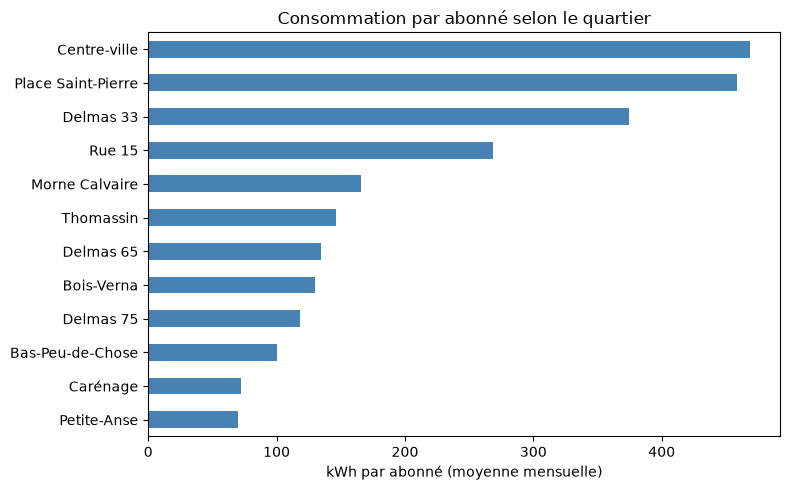

In [12]:
par_type = conso.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Consommation moyenne par abonné selon le type :")
print(par_type)
print()

classement = conso.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)
print("Classement des 12 quartiers :")
print(classement)

classement.sort_values().plot.barh(figsize=(8, 5), color="steelblue")
plt.xlabel("kWh par abonné (moyenne mensuelle)")
plt.ylabel("")
plt.title("Consommation par abonné selon le quartier")
plt.tight_layout()
plt.show()

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Consommation totale par commune et par année, hausse en % , puis les totaux en millions de kWh.

                2024 (millions de kWh)  2025 (millions de kWh)  hausse (%)
commune                                                                   
Cap-Haïtien                       4.59                    5.62        22.5
Pétion-Ville                      8.60                    9.68        12.6
Port-au-Prince                   10.09                   10.31         2.3
Delmas                           11.61                   11.74         1.1


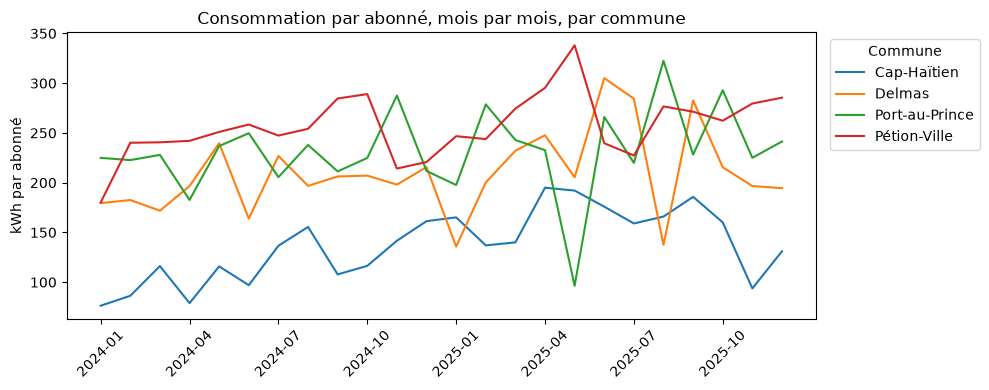

In [ ]:
totaux = conso.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")

hausse = (totaux[2025] / totaux[2024] - 1) * 100

tableau = pd.DataFrame({
    "2024 (millions de kWh)": (totaux[2024] / 1e6).round(2),
    "2025 (millions de kWh)": (totaux[2025] / 1e6).round(2),
    "hausse (%)": hausse.round(1),
}).sort_values("hausse (%)", ascending=False)
print(tableau)

courbes = conso.groupby(["mois", "commune"])["kwh_par_abonne"].mean().unstack()
courbes.plot(figsize=(10, 4))
plt.ylabel("kWh par abonné")
plt.xlabel("")
plt.title("Consommation par abonné, mois par mois, par commune")
plt.xticks(range(0, len(courbes), 3), courbes.index[::3], rotation=45)
plt.legend(title="Commune", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement.

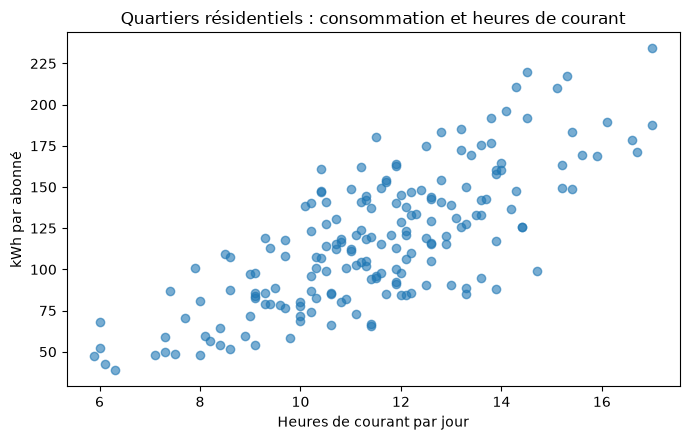

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [14]:
residentiels = conso[conso["type"] == "Résidentiel"]

plt.figure(figsize=(7, 4.5))
plt.scatter(residentiels["heures_courant"], residentiels["kwh_par_abonne"], alpha=0.6)
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.title("Quartiers résidentiels : consommation et heures de courant")
plt.tight_layout()
plt.show()

corr_courant = residentiels["kwh_par_abonne"].corr(residentiels["heures_courant"])
corr_temperature = residentiels["kwh_par_abonne"].corr(residentiels["temperature_c"])
print("Corrélation avec les heures de courant :", round(corr_courant, 2))
print("Corrélation avec la température :", round(corr_temperature, 2))

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant.

                  Q1  médiane    Q3
commune                            
Cap-Haïtien      8.3     10.0  11.7
Delmas          10.1     11.9  13.0
Port-au-Prince  10.7     11.6  13.1
Pétion-Ville    10.4     11.6  13.0


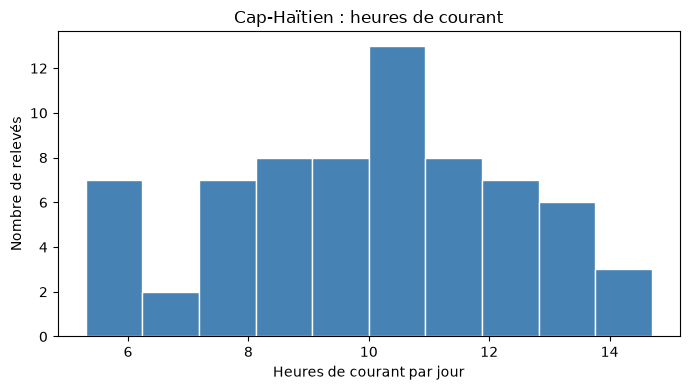

Relevés de 2025 avec moins de 8 heures de courant par jour : 3
        mois   quartier  heures_courant
81   2025-01  Delmas 33             7.4
227  2025-08   Carénage             7.3
253  2025-11     Rue 15             5.9


In [15]:
quartiles = conso.groupby("commune")["heures_courant"].quantile([0.25, 0.5, 0.75]).unstack()
quartiles.columns = ["Q1", "médiane", "Q3"]
print(quartiles.round(1))

cap = conso[conso["commune"] == "Cap-Haïtien"]
plt.figure(figsize=(7, 4))
plt.hist(cap["heures_courant"], bins=10, color="steelblue", edgecolor="white")
plt.xlabel("Heures de courant par jour")
plt.ylabel("Nombre de relevés")
plt.title("Cap-Haïtien : heures de courant")
plt.tight_layout()
plt.show()

faibles = conso[(conso["annee"] == 2025) & (conso["heures_courant"] < 8)]
print("Relevés de 2025 avec moins de 8 heures de courant par jour :", len(faibles))
print(faibles[["mois", "quartier", "heures_courant"]])

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations : mois, quartier, type, kwh.

In [16]:
plus_gros = conso.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print(plus_gros.to_string(index=False))

   mois     quartier       type    kwh
2025-07    Delmas 33 Commercial 742780
2024-11 Centre-ville Commercial 597730
2025-09    Delmas 33 Commercial 591420


## 9. Conclusion

Dans les quartiers résidentiels, la consommation par abonné suit les heures de courant (corrélation de 0,76) et non la chaleur (corrélation de -0,15 avec la température). Une corrélation montre seulement que deux séries varient ensemble : elle ne prouve pas que plus d'heures de courant *provoquent* plus de consommation, ni qu'aucun autre facteur (type de quartier, nombre d'appareils, tarif) n'intervient. Pour trancher, il faudrait comparer un même quartier avant et après un changement de ses heures de courant.